<div style="display:block;width:100%;margin:auto;" direction=rtl align=center>
    <br><br>
    <div style="width:100%;margin:100;display:block;background-color:#fff0;" display=block align=center>
        <table style="border-style:hidden;border-collapse:collapse;">
            <tr>
                <td style="border: none!important;">
                    <img width=130 align=right src="https://i.ibb.co/yXKQmtZ/logo1.png" style="margin:0;" />
                </td>
                <td style="text-align:center;border: none!important;">
                    <h1 align=center><font size=5 color="#045F5F"> <b> Neural networks and deep learning</b><br><br>Computer Assignment 5</font></h1>
                </td>
                <td style="border: none!important;">
                    <img width=170 align=left src="https://i.ibb.co/wLjqFkw/logo2.png" style="margin:0;" />
                </td>
            </tr>
        </table>
        <h1> Instructor: Dr. Ahmad Kalhor   </h1>
    </div>
</div>


In [ ]:
# !pip install torchmetrics

<div dir="rtl">

# ایمپورت کتابخانه های مورد استفاده

In [2]:
import os

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader, random_split, Dataset

import torchvision
from torchvision import transforms as T
from torchvision.datasets import ImageFolder
import torchvision.models as models

from PIL import Image
from io import BytesIO

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

import numpy as np
import pandas as pd

import pickle

from torchmetrics import Accuracy
from tqdm import tqdm



<div dir="rtl">

# تعریف device

In [3]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

<div dir="rtl">

# انتقال دادگان به colab و بررسی فایل های موجود

In [4]:
!git lfs install
!git clone https://huggingface.co/datasets/ArianFiroozi/NNDL_HW5_S2025

Git LFS initialized.
Cloning into 'NNDL_HW5_S2025'...
remote: Enumerating objects: 33, done.
remote: Total 33 (delta 0), reused 0 (delta 0), pack-reused 33 (from 1)
Unpacking objects: 100% (33/33), 10.81 KiB | 1.54 MiB/s, done.


In [5]:
os.listdir("NNDL_HW5_S2025")

['README.md', '.gitattributes', 'data', '.git']

In [6]:
with open("NNDL_HW5_S2025/README.md", "r") as f:
    print(f.read())

---
dataset_info:
  features:
  - name: image
    dtype: image
  - name: label
    dtype: int64
  - name: disease_name
    dtype: string
  splits:
  - name: train
    num_bytes: 158095134.4
    num_examples: 9325
  download_size: 157072834
  dataset_size: 158095134.4
configs:
- config_name: default
  data_files:
  - split: train
    path: data/train-*
task_categories:
- image-classification
pretty_name: TomatoDisease
---
# Dataset Card for "NNDL_HW5_S2025"

This is a dataset created for neural networks and deep learning course at University of Tehran. The original data can be accessed at https://www.kaggle.com/datasets/emmarex/plantdisease/data

[More Information needed](https://github.com/huggingface/datasets/blob/main/CONTRIBUTING.md#how-to-contribute-to-the-dataset-cards)


In [7]:
os.listdir("NNDL_HW5_S2025/data")

['train-00000-of-00001-982530f49cf10cee.parquet']

<div dir="rtl">

# نمایش یک نمونه از هر کلاس در مجوعه دادگان

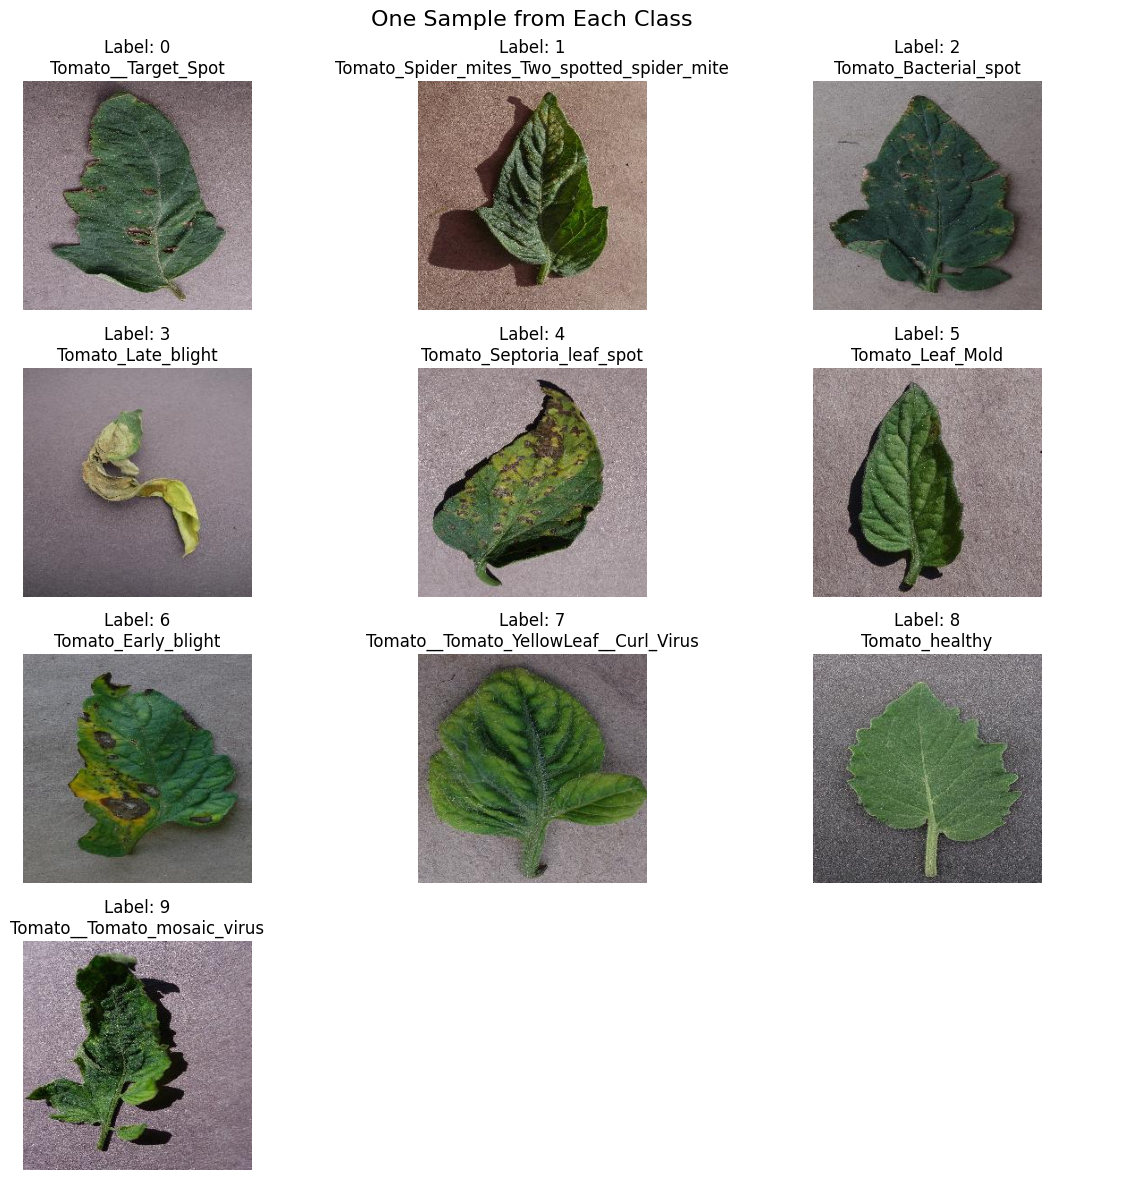

In [8]:
# Load the dataset
df = pd.read_parquet("NNDL_HW5_S2025/data/train-00000-of-00001-982530f49cf10cee.parquet")

# Dictionary to store one sample per class
label_samples = {}

# Collect one sample image for each unique label
for i in range(len(df)):
    label_id = df.iloc[i]['label']
    label_name = df.iloc[i]['disease_name']

    if label_id not in label_samples:
        img_bytes = df.iloc[i]['image']['bytes']
        image = Image.open(BytesIO(img_bytes))
        label_samples[label_id] = (image, label_name)

    if len(label_samples) == 10:
        break

# Sort the samples by label_id
sorted_labels = sorted(label_samples.items(), key=lambda x: x[0])

# Plot images in a 4x3 grid (only 10 images, so last 2 slots will be empty)
fig, axes = plt.subplots(4, 3, figsize=(12, 12))
fig.suptitle("One Sample from Each Class", fontsize=16)

for idx, (label_id, (image, label_name)) in enumerate(sorted_labels):
    row, col = divmod(idx, 3)
    axes[row, col].imshow(image)
    axes[row, col].set_title(f"Label: {label_id}\n{label_name}")
    axes[row, col].axis('off')

# Hide any unused subplots (in this case, last 2)
for idx in range(len(sorted_labels), 12):
    row, col = divmod(idx, 3)
    axes[row, col].axis('off')

plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()


<div dir="rtl">

# بررسی توازن بین دادگان

Absolute class counts:
label
0    1000
1    1000
2    1000
3    1000
4    1000
5     952
6    1000
7    1000
8    1000
9     373
Name: count, dtype: int64


Class distribution (percentage):
label
0    10.72
1    10.72
2    10.72
3    10.72
4    10.72
5    10.21
6    10.72
7    10.72
8    10.72
9     4.00
Name: count, dtype: float64


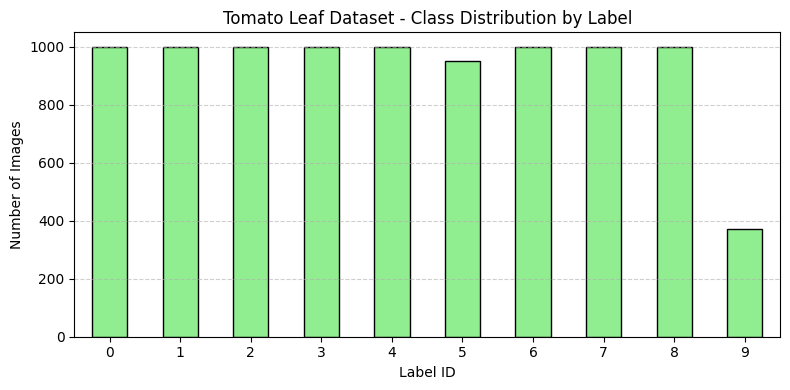

In [9]:
# Count number of samples per label (numeric class ID)
label_counts = df['label'].value_counts().sort_index()

# Print absolute class counts
print("Absolute class counts:")
print(label_counts)
print("\n")

# Print relative class percentages
print("Class distribution (percentage):")
print((label_counts / len(df) * 100).round(2))

# Plot bar chart of label distribution
plt.figure(figsize=(8, 4))
label_counts.plot(kind='bar', color='lightgreen', edgecolor='black')
plt.title("Tomato Leaf Dataset - Class Distribution by Label")
plt.xlabel("Label ID")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()



<div dir="rtl">

# تقسیم بندی دادگان به داده های train, validation

In [10]:
# 80% train, 20% validation with stratified sampling based on 'label'
train_df, val_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df['label'],
    random_state=42
)

# Check the number of samples
print(f"Train size: {len(train_df)}")
print(f"Validation size: {len(val_df)}")

Train size: 7460
Validation size: 1865


<div dir="rtl">

# متوازن کردن دادگان train (balanced_train_df)



Balanced class distribution by label:
label
0    800
1    800
2    800
3    800
4    800
5    800
6    800
7    800
8    800
9    800
Name: count, dtype: int64


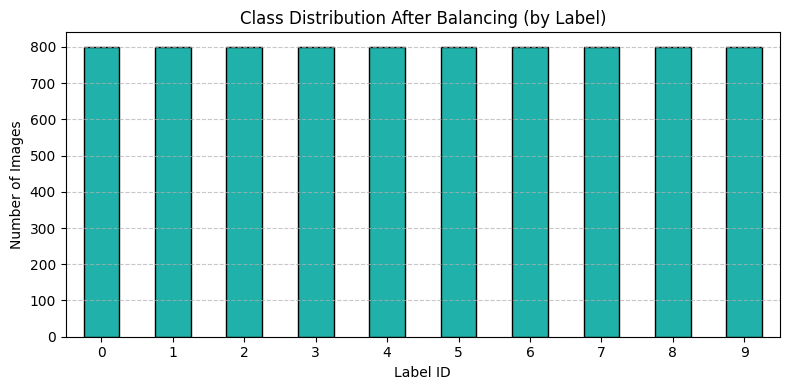

In [11]:
# Count images per class
class_counts = train_df['disease_name'].value_counts()
max_count = class_counts.max()

# List to store augmented rows
augmented_rows = []

# Define data augmentation: flip + zoom + slight brightness change
augment_transform = T.Compose([
    T.RandomHorizontalFlip(p=0.75),
    T.RandomResizedCrop(size=256, scale=(0.9, 1.0)),  # up to 10% zoom
    T.ColorJitter(brightness=0.1)  # small brightness variation
])

# Loop over each underrepresented class
for disease_name, count in class_counts.items():
    if count >= max_count:
        continue  # Already balanced

    df_class = train_df[train_df['disease_name'] == disease_name]
    num_to_add = max_count - count
    available = len(df_class)

    # Step 1: use all unique samples first
    if num_to_add <= available:
        sampled_rows = df_class.sample(n=num_to_add, replace=False, random_state=42)
    else:
        # Use all available unique samples
        sampled_rows = df_class.copy()

        # Then sample extra needed with replacement
        remaining = num_to_add - available
        sampled_extra = df_class.sample(n=remaining, replace=True, random_state=42)

        # Combine both
        sampled_rows = pd.concat([sampled_rows, sampled_extra], ignore_index=True)

    # Apply augmentation to each sampled row
    for _, row in sampled_rows.iterrows():
        img = Image.open(BytesIO(row['image']['bytes'])).convert('RGB')
        augmented_img = augment_transform(img)

        buffer = BytesIO()
        augmented_img.save(buffer, format="JPEG")
        augmented_bytes = buffer.getvalue()

        new_row = {
            'image': {
                'bytes': augmented_bytes,
                'path': row['image']['path'] + '_aug'
            },
            'label': row['label'],
            'disease_name': row['disease_name']
        }
        augmented_rows.append(new_row)

# Combine augmented data with original training data
aug_df = pd.DataFrame(augmented_rows)
balanced_train_df = pd.concat([train_df, aug_df], ignore_index=True)

# Shuffle the final dataset
balanced_train_df = balanced_train_df.sample(frac=1.0, random_state=42).reset_index(drop=True)

# Final class distribution by label
final_label_counts = balanced_train_df['label'].value_counts().sort_index()

print("Balanced class distribution by label:")
print(final_label_counts)

# Plot distribution by label
plt.figure(figsize=(8, 4))
final_label_counts.plot(kind='bar', color='lightseagreen', edgecolor='black')
plt.title("Class Distribution After Balancing (by Label)")
plt.xlabel("Label ID")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


<div dir="rtl">

# ساخت Custom Dataset

In [12]:
class TomatoDataset(Dataset):
    def __init__(self, dataframe, train=False, vit=False):
        self.df = dataframe.reset_index(drop=True)
        self.train = train
        self.vit = vit

        # Set resize size based on ViT flag
        resize_size = 80 if self.vit else 299

        # Define transforms
        if self.train:
            self.transform = T.Compose([
                T.RandomHorizontalFlip(),
                T.RandomResizedCrop(size=256, scale=(0.9, 1.0)),  # up to 10% zoom
                T.Resize((resize_size, resize_size)),
                T.ToTensor(),
                T.Normalize(mean=[0.485, 0.456, 0.406],
                                     std=[0.229, 0.224, 0.225])
            ])
        else:
            self.transform = T.Compose([
                T.Resize((resize_size, resize_size)),
                T.ToTensor(),
                T.Normalize(mean=[0.485, 0.456, 0.406],
                                     std=[0.229, 0.224, 0.225])
            ])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_bytes = row['image']['bytes']
        label = row['label']

        image = Image.open(BytesIO(img_bytes)).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label


<div dir="rtl">

# توابع مورد نیاز برای آموزش مدل های مختلف

In [13]:
class AverageMeter(object):
    """Computes and stores the average and current value"""
    def __init__(self):
        self.reset()

    def reset(self):
        self.val = 0
        self.avg = 0
        self.sum = 0
        self.count = 0

    def update(self, val, n=1):
        self.val = val
        self.sum += val * n
        self.count += n
        self.avg = self.sum / self.count

In [14]:
def train_one_epoch(model, train_loader, loss_fn, optimizer, epoch=None, use_aux=False):
    model.train()
    loss_train = AverageMeter()
    acc_train  = Accuracy(task='multiclass', num_classes=10).to(device)

    with tqdm(train_loader, unit="batch") as tepoch:
        for inputs, targets in tepoch:
            if epoch is not None:
                tepoch.set_description(f"Epoch {epoch}")
            inputs = inputs.to(device)
            targets = targets.to(device)

            # Forward pass
            if use_aux:
                outputs, aux_outputs = model(inputs)
                loss_main = loss_fn(outputs, targets)
                loss_aux = loss_fn(aux_outputs, targets)
                loss = loss_main + 0.4 * loss_aux  # typical weighting for aux loss
            else:
                outputs = model(inputs)
                loss = loss_fn(outputs, targets)

            # Backpropagation
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

            # Metrics
            loss_train.update(loss.item())
            acc_train(outputs, targets.int())

            tepoch.set_postfix(loss=loss_train.avg,
                               accuracy=100. * acc_train.compute().item())

    return model, loss_train.avg, acc_train.compute().item()


In [15]:
def validation(model, test_loader, loss_fn):
  model.eval()
  with torch.no_grad():
    loss_valid = AverageMeter()
    acc_valid = Accuracy(task='multiclass', num_classes=10).to(device)
    for i, (inputs, targets) in enumerate(test_loader):
      inputs = inputs.to(device)
      targets = targets.to(device)

      outputs = model(inputs)
      loss = loss_fn(outputs, targets)

      loss_valid.update(loss.item())
      acc_valid(outputs, targets.int())
  return loss_valid.avg, acc_valid.compute().item()

<div dir="rtl">

# تابع تعداد پارامترهای مدل

In [16]:
def num_params(model):
  nums = sum(p.numel() for p in model.parameters())/1e6
  return nums

In [17]:
def num_trainable_params(model):
    # Sum all parameters that require gradients (p.requires_grad == True)
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return trainable_params / 1e6  # Convert to millions

<div dir="rtl">

# تابع رسم نمودارهای accuracy, loss برای داده های train, validation

In [18]:
def plots_(caption):
    # Create figure with two subplots (Loss & Accuracy)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))
    fig.suptitle(caption +'\s Model Performance', fontsize=16, y=1.05)

    # ========== LOSS PLOT ==========
    ax1.plot(loss_train_hist,
            label='Training Loss',
            color='#1f77b4',  # Blue
            linestyle='-',
            linewidth=2,
            marker='o',
            markersize=5)

    ax1.plot(loss_valid_hist,
            label='Validation Loss',
            color='#ff7f0e',  # Orange
            linestyle='-',
            linewidth=2,
            marker='s',
            markersize=5)

    ax1.set_title('Training vs Validation Loss', fontsize=14, pad=15)
    ax1.set_xlabel('Epochs', fontsize=12)
    ax1.set_ylabel('Loss Value', fontsize=12)
    ax1.legend(fontsize=11, framealpha=0.9)
    ax1.grid(True, linestyle=':', alpha=0.7)

    # Highlight minimum validation loss
    min_loss_val = min(loss_valid_hist)
    min_loss_epoch = loss_valid_hist.index(min_loss_val)
    ax1.axvline(x=min_loss_epoch, color='r', linestyle='--', alpha=0.5)
    ax1.annotate(f'Min Val Loss: {min_loss_val:.4f}',
                xy=(min_loss_epoch, min_loss_val),
                xytext=(10, 10),
                textcoords='offset points',
                bbox=dict(boxstyle='round,pad=0.5', fc='yellow', alpha=0.5))

    # ========== ACCURACY PLOT ==========
    ax2.plot(acc_train_hist,
            label='Training Accuracy',
            color='#2ca02c',  # Green
            linestyle='-',
            linewidth=2,
            marker='^',
            markersize=5)

    ax2.plot(acc_valid_hist,
            label='Validation Accuracy',
            color='#d62728',  # Red
            linestyle='-',
            linewidth=2,
            marker='D',
            markersize=5)

    ax2.set_title('Training vs Validation Accuracy', fontsize=14, pad=15)
    ax2.set_xlabel('Epochs', fontsize=12)
    ax2.set_ylabel('Accuracy (%)', fontsize=12)
    ax2.legend(fontsize=11, framealpha=0.9)
    ax2.grid(True, linestyle=':', alpha=0.7)

    # Highlight maximum validation accuracy
    max_acc_val = max(acc_valid_hist)
    max_acc_epoch = acc_valid_hist.index(max_acc_val)
    ax2.axvline(x=max_acc_epoch, color='g', linestyle='--', alpha=0.5)
    ax2.annotate(f'Max Val Acc: {max_acc_val:.2f}%',
                xy=(max_acc_epoch, max_acc_val),
                xytext=(10, -20),
                textcoords='offset points',
                bbox=dict(boxstyle='round,pad=0.5', fc='yellow', alpha=0.5))

    # Adjust layout
    plt.tight_layout()

<div dir="rtl">

# تابع ارزیابی مدل با داده های test

In [19]:
def evaluate_model_to_dataframe(model, test_loader, device='cuda' if torch.cuda.is_available() else 'cpu'):
    """Evaluate model and return metrics as DataFrames"""
    model.to(device)
    model.eval()
    all_targets = []
    all_predictions = []

    with torch.no_grad():
        for inputs, targets in test_loader:
            inputs = inputs.to(device)
            targets = targets.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_targets.extend(targets.cpu().numpy())
            all_predictions.extend(preds.cpu().numpy())

    # Convert to numpy arrays
    y_true = np.array(all_targets)
    y_pred = np.array(all_predictions)

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    classes = [f'Class {i}' for i in range(len(np.unique(y_true)))]
    cm_df = pd.DataFrame(cm, index=[f'True {c}' for c in classes],
                         columns=[f'Pred {c}' for c in classes])

    # Classification Report
    report = classification_report(y_true, y_pred, target_names=classes, output_dict=True)
    report_df = pd.DataFrame(report).transpose().round(4)

    # Plot confusion matrix
    plt.figure(figsize=(5,5))
    sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title('Confusion Matrix', pad=20)
    plt.xlabel('Predicted Labels', labelpad=10)
    plt.ylabel('True Labels', labelpad=10)
    plt.show()

    return {
        'confusion_matrix': cm_df,
        'classification_report': report_df,
        'true_labels': y_true,
        'pred_labels': y_pred
    }


<div dir="rtl">

# Inception-V3 model

<div dir="rtl">

## تعریف dataset ها

In [ ]:
train_ds = TomatoDataset(balanced_train_df, train=True, vit=False)
val_ds   = TomatoDataset(val_df, train=False, vit=False)

<div dir="rtl">

## تعریف dataloader ها

In [ ]:
train_loader = DataLoader(
    train_ds,
    batch_size=32,
    shuffle=True,
    num_workers=8,
    prefetch_factor=8,
    pin_memory=True
)
val_loader = DataLoader(
    val_ds,
    batch_size=32,
    shuffle=True,
    num_workers=8,
    prefetch_factor=8,
    pin_memory=True
)


<div dir="rtl">

## تعریف کلاس مدل inception

In [ ]:
class InceptionClass(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        # Load pretrained InceptionV3 with aux_logits enabled
        self.inception = models.inception_v3(pretrained=False, aux_logits=True)


        in_features = self.inception.fc.in_features
        self.inception.fc = nn.Sequential(
            nn.Linear(in_features, 1024),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(1024, num_classes)
        )

        # Replace auxiliary classifier too
        if self.inception.aux_logits:
            in_aux_features = self.inception.AuxLogits.fc.in_features
            self.inception.AuxLogits.fc = nn.Sequential(
                nn.Linear(in_aux_features, 512),
                nn.ReLU(),
                nn.Dropout(0.3),
                nn.Linear(512, num_classes)
            )

    def forward(self, x):
        if self.training:
            x, aux = self.inception(x)
            return x, aux
        else:
            x = self.inception(x)
            return x


<div dir="rtl">

## تعیین نرخ یادگیری

In [ ]:
loss_fn = nn.CrossEntropyLoss()
num_epochs = 4
for lr in [0.1, 0.01, 0.001, 0.0001]:
  print(f'LR={lr}')
  model = InceptionClass(num_classes=10).to(device)
  optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=0)
  for epoch in range(num_epochs):
    model, _, _ = train_one_epoch(model, train_loader, loss_fn, optimizer, epoch, use_aux=True)
  print()

LR=0.1


Epoch 3: 100%|██████████| 250/250 [00:46<00:00,  5.41batch/s, accuracy=9.72, loss=3.46]



LR=0.01


Epoch 3: 100%|██████████| 250/250 [00:47<00:00,  5.31batch/s, accuracy=30.3, loss=2.5]



LR=0.001


Epoch 3: 100%|██████████| 250/250 [00:47<00:00,  5.29batch/s, accuracy=84.4, loss=0.632]



LR=0.0001


Epoch 3: 100%|██████████| 250/250 [00:47<00:00,  5.30batch/s, accuracy=86.5, loss=0.529]

<div dir="rtl">

## تعریف مدل مقاله، تعداد پارامترهای قابل آموزش و خلاصه ای از مدل

In [ ]:
model = InceptionClass(num_classes=10).to(device)

/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/torchvision/models/inception.py:43: FutureWarning: The default weight initialization of inception_v3 will be changed in future releases of torchvision. If you wish to keep the old behavior (which leads to long initialization times due to scipy/scipy#11299), please set init_weights=True.
  warnings.warn(


In [ ]:
num_trainable_params(model) #*1e6(milion)

26.850548

In [ ]:
model

InceptionClass(
  (inception): Inception3(
    (Conv2d_1a_3x3): BasicConv2d(
      (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), bias=False)
      (bn): BatchNorm2d(32, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
    )
    (Conv2d_2a_3x3): BasicConv2d(
      (conv): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), bias=False)
      (bn): BatchNorm2d(32, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
    )
    (Conv2d_2b_3x3): BasicConv2d(
      (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(64, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
    )
    (maxpool1): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (Conv2d_3b_1x1): BasicConv2d(
      (conv): Conv2d(64, 80, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn): BatchNorm2d(80, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
    )
    (Conv2d_4a_3x3)

<div dir="rtl">

## Compile کردن مدل

In [ ]:
# Change to Adam optimizer with learning rate 0.001
optimizer = optim.Adam(model.parameters(),
                        lr=0.0001,
                        betas=(0.9, 0.999),
                        eps=1e-07,
                        weight_decay=.0000,
                        amsgrad=False)

loss_fn = nn.CrossEntropyLoss()

<div dir="rtl">

## fit کردن مدل

In [ ]:
loss_train_hist = []
loss_valid_hist = []

acc_train_hist = []
acc_valid_hist = []

best_loss_valid = torch.inf
epoch_counter = 0

In [ ]:
num_epochs = 30

for epoch in range(num_epochs):
  # Train
  model, loss_train, acc_train = train_one_epoch(model,
                                                 train_loader,
                                                 loss_fn,
                                                 optimizer,
                                                 epoch,
                                                 use_aux=True)
  # Validation
  loss_valid, acc_valid = validation(model,
                                     val_loader,
                                     loss_fn)

  loss_train_hist.append(loss_train)
  loss_valid_hist.append(loss_valid)

  acc_train_hist.append(acc_train)
  acc_valid_hist.append(acc_valid)

  if loss_valid < best_loss_valid:
    torch.save(model, f'model.pt')
    best_loss_valid = loss_valid

  print(f'Valid: Loss = {loss_valid:.4}, Acc = {acc_valid:.4}')
  print()

  epoch_counter += 1

Epoch 0: 100%|██████████| 250/250 [00:47<00:00,  5.27batch/s, accuracy=52.1, loss=1.93]


Valid: Loss = 0.7403, Acc = 0.7324



Epoch 1: 100%|██████████| 250/250 [00:47<00:00,  5.28batch/s, accuracy=78, loss=0.852]


Valid: Loss = 0.5301, Acc = 0.8198



Epoch 2: 100%|██████████| 250/250 [00:47<00:00,  5.27batch/s, accuracy=83.4, loss=0.635]


Valid: Loss = 0.3873, Acc = 0.866



... (50 outputs left out)

Epoch 28: 100%|██████████| 250/250 [00:47<00:00,  5.28batch/s, accuracy=97, loss=0.113]


Valid: Loss = 0.1023, Acc = 0.9689



Epoch 29: 100%|██████████| 250/250 [00:47<00:00,  5.29batch/s, accuracy=97.5, loss=0.0974]


Valid: Loss = 0.08557, Acc = 0.9727



In [ ]:
model = torch.load('model.pt',  # Model file
                  map_location='cpu',  # Load to CPU (change to 'cuda' for GPU)
                  weights_only=False)  # Set to True for safer loading (PyTorch 2.6+)

<div dir="rtl">

## رسم نمودارهای تابع هزینه و دقت در طول آموزش

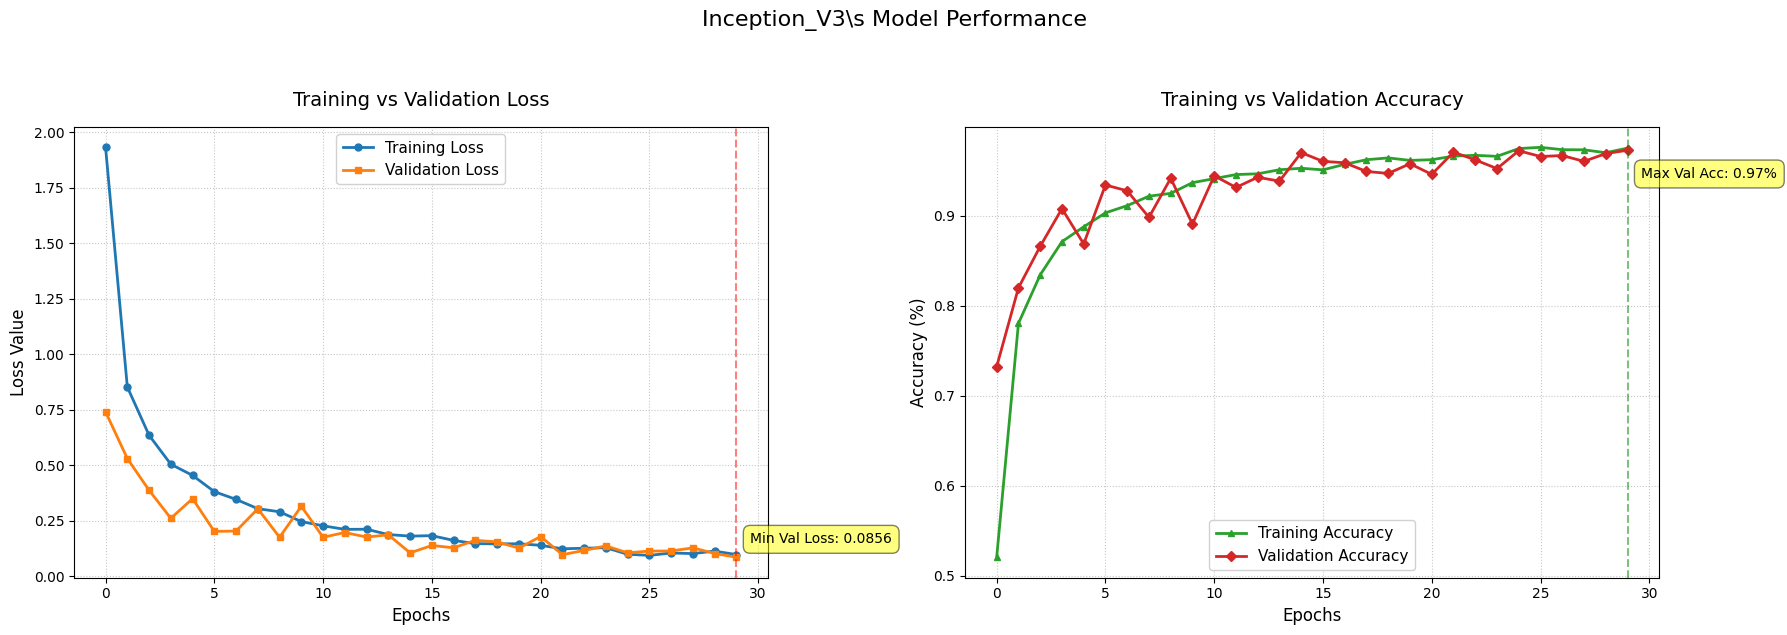

In [ ]:
plots_('Inception_V3')

<div dir="rtl">

## ارزیابی مدل با داده های تست

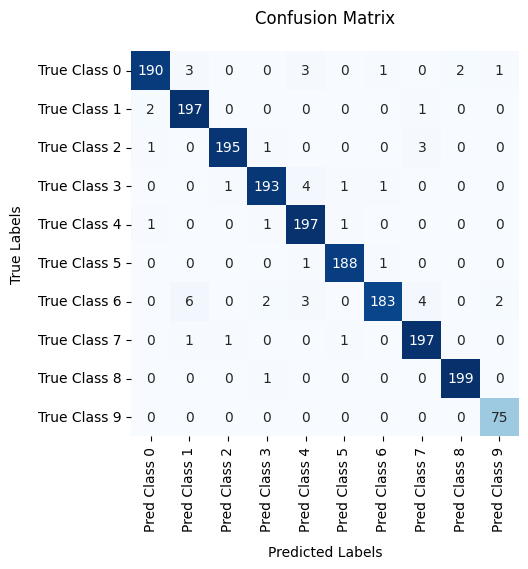

Confusion Matrix:


,Pred Class 0,Pred Class 1,Pred Class 2,Pred Class 3,Pred Class 4,Pred Class 5,Pred Class 6,Pred Class 7,Pred Class 8,Pred Class 9
True Class 0,190,3,0,0,3,0,1,0,2,1
True Class 1,2,197,0,0,0,0,0,1,0,0
True Class 2,1,0,195,1,0,0,0,3,0,0
True Class 3,0,0,1,193,4,1,1,0,0,0
True Class 4,1,0,0,1,197,1,0,0,0,0
True Class 5,0,0,0,0,1,188,1,0,0,0
True Class 6,0,6,0,2,3,0,183,4,0,2
True Class 7,0,1,1,0,0,1,0,197,0,0
True Class 8,0,0,0,1,0,0,0,0,199,0
True Class 9,0,0,0,0,0,0,0,0,0,75



Classification Report:


,precision,recall,f1-score,support
Class 0,0.9794,0.9500,0.9645,200.0
Class 1,0.9517,0.9850,0.9681,200.0
Class 2,0.9898,0.9750,0.9824,200.0
Class 3,0.9747,0.9650,0.9698,200.0
Class 4,0.9471,0.9850,0.9657,200.0
Class 5,0.9843,0.9895,0.9869,190.0
Class 6,0.9839,0.9150,0.9482,200.0
Class 7,0.9610,0.9850,0.9728,200.0
Class 8,0.9900,0.9950,0.9925,200.0
Class 9,0.9615,1.0000,0.9804,75.0


accuracy 0.9727


In [ ]:
results = evaluate_model_to_dataframe(model, val_loader)
print("Confusion Matrix:")
display(results['confusion_matrix'])
print("\nClassification Report:")
display(results['classification_report'][:10])
print('accuracy', float(results['classification_report'].iloc[10]['precision']))

<div dir="rtl">

# ViT model

<div dir="rtl">

## تعریف dataset ها

In [20]:
train_ds = TomatoDataset(balanced_train_df, train=True, vit=True)
val_ds   = TomatoDataset(val_df, train=False, vit=True)

<div dir="rtl">

## تعریف dataloader ها

In [21]:
train_loader = DataLoader(
    train_ds,
    batch_size=256,
    shuffle=True,
    num_workers=8,
    prefetch_factor=8,
    pin_memory=True
)
val_loader = DataLoader(
    val_ds,
    batch_size=256,
    shuffle=True,
    num_workers=8,
    prefetch_factor=8,
    pin_memory=True
)


<div dir="rtl">

## تعریف کلاس مدل ViT

In [22]:
# -----------------------------
# Projection Block (repeated ×8)
# -----------------------------
class ProjectionBlock(nn.Module):
    def __init__(self, dim=64, mlp_dim=128, dropout=0.1):
        super().__init__()
        self.fc1 = nn.Linear(dim, mlp_dim)
        self.fc2 = nn.Linear(mlp_dim, dim)
        self.dropout = nn.Dropout(dropout)
        self.norm = nn.LayerNorm(dim)

    def forward(self, x):
        residual = x
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        x = self.dropout(x)
        x = self.norm(x + residual)
        return x

# -----------------------------
# Transformer Encoder Block
# -----------------------------
class TransformerEncoderBlock(nn.Module):
    def __init__(self, emb_dim=64, mlp_dim=128, num_heads=2, dropout=0.1):
        super().__init__()
        self.attn = nn.MultiheadAttention(embed_dim=emb_dim, num_heads=num_heads, batch_first=True)
        self.attn_norm = nn.LayerNorm(emb_dim)

        self.ffn = nn.Sequential(
            nn.Linear(emb_dim, mlp_dim),
            nn.ReLU(),
            nn.Linear(mlp_dim, emb_dim),
            nn.Dropout(dropout)
        )
        self.ffn_norm = nn.LayerNorm(emb_dim)

    def forward(self, x):
        attn_out, _ = self.attn(x, x, x)
        x = self.attn_norm(x + attn_out)
        ffn_out = self.ffn(x)
        x = self.ffn_norm(x + ffn_out)
        return x

# -----------------------------
# ViT Model with patchify and embedding tracking
# -----------------------------
class ViTArticleModel(nn.Module):
    def __init__(self,
                 num_patches=100,
                 patch_dim=192,
                 emb_dim=64,
                 projection_depth=8,
                 encoder_layers=1,
                 num_heads=2,
                 mlp_dim=128,
                 num_classes=10):
        super().__init__()

        self.patch_dim = patch_dim
        self.num_patches = num_patches
        self.emb_dim = emb_dim

        # Linear projection to embedding dimension
        self.patch_embedding = nn.Linear(patch_dim, emb_dim)

        # Learnable positional embeddings
        self.pos_embed = nn.Embedding(num_patches, emb_dim)
        nn.init.trunc_normal_(self.pos_embed.weight, std=0.02)

        # Stack of projection blocks
        self.projection_blocks = nn.Sequential(*[
            ProjectionBlock(dim=emb_dim, mlp_dim=mlp_dim)
            for _ in range(projection_depth)
        ])

        # Stack of Transformer encoder blocks
        self.encoder_blocks = nn.Sequential(*[
            TransformerEncoderBlock(emb_dim=emb_dim, mlp_dim=mlp_dim, num_heads=num_heads)
            for _ in range(encoder_layers)
        ])

        # MLP classifier head
        self.classifier = nn.Sequential(
            nn.Flatten(),  # (B, 100, 64) → (B, 6400)
            nn.Linear(num_patches * emb_dim, 2048),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(2048, 1024),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(1024, num_classes)
        )

        # Store patch embedding for visualization (bonus question)
        self.last_patch_embedding = None

    def patchify(self, x, patch_size=8):
        B, C, H, W = x.shape
        assert H % patch_size == 0 and W % patch_size == 0
        x = x.unfold(2, patch_size, patch_size).unfold(3, patch_size, patch_size)
        x = x.contiguous().view(B, C, -1, patch_size, patch_size)
        x = x.permute(0, 2, 1, 3, 4)  # (B, num_patches, C, pH, pW)
        x = x.reshape(B, x.size(1), -1)  # (B, 100, 192)
        return x

    def forward(self, x):
        # If input is raw image, apply patchify
        if x.dim() == 4 and x.shape[2:] == (80, 80):
            x = self.patchify(x)

        # Patch embedding
        x = self.patch_embedding(x)  # (B, 100, 64)

        # Save for visualization
        self.last_patch_embedding = x.detach()



        # Apply projection blocks and transformer encoder
        x = self.projection_blocks(x)

        # Add positional encoding
        B, N, _ = x.shape
        pos = torch.arange(N, device=x.device).unsqueeze(0).expand(B, N)
        x = x + self.pos_embed(pos)


        x = self.encoder_blocks(x)

        # Classifier head
        return self.classifier(x)


<div dir="rtl">

## تعریف مدل، تعداد پارامترهای قابل آموزش و خلاصه ای از مدل

In [23]:
model = ViTArticleModel().to(device)
model

ViTArticleModel(
  (patch_embedding): Linear(in_features=192, out_features=64, bias=True)
  (pos_embed): Embedding(100, 64)
  (projection_blocks): Sequential(
    (0): ProjectionBlock(
      (fc1): Linear(in_features=64, out_features=128, bias=True)
      (fc2): Linear(in_features=128, out_features=64, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
    )
    (1): ProjectionBlock(
      (fc1): Linear(in_features=64, out_features=128, bias=True)
      (fc2): Linear(in_features=128, out_features=64, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
    )
    (2): ProjectionBlock(
      (fc1): Linear(in_features=64, out_features=128, bias=True)
      (fc2): Linear(in_features=128, out_features=64, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
    )
    (3): Proj

In [24]:
num_trainable_params(model) #*1e6(milion)

15.40353

<div dir="rtl">

## Compile کردن مدل

In [25]:
# Change to Adam optimizer with learning rate 0.001
optimizer = optim.Adam(model.parameters(),
                        lr=0.0001,
                        betas=(0.9, 0.999),
                        eps=1e-07,
                        weight_decay=.0000,
                        amsgrad=False)

loss_fn = nn.CrossEntropyLoss()

<div dir="rtl">

## fit کردن مدل

In [26]:
loss_train_hist = []
loss_valid_hist = []

acc_train_hist = []
acc_valid_hist = []

best_loss_valid = torch.inf
epoch_counter = 0

In [27]:
num_epochs = 30

for epoch in range(num_epochs):
  # Train
  model, loss_train, acc_train = train_one_epoch(model,
                                                 train_loader,
                                                 loss_fn,
                                                 optimizer,
                                                 epoch,
                                                 use_aux=False)
  # Validation
  loss_valid, acc_valid = validation(model,
                                     val_loader,
                                     loss_fn)

  loss_train_hist.append(loss_train)
  loss_valid_hist.append(loss_valid)

  acc_train_hist.append(acc_train)
  acc_valid_hist.append(acc_valid)

  if loss_valid < best_loss_valid:
    torch.save(model, f'model.pt')
    best_loss_valid = loss_valid

  print(f'Valid: Loss = {loss_valid:.4}, Acc = {acc_valid:.4}')
  print()

  epoch_counter += 1

Epoch 0: 100%|██████████| 32/32 [00:04<00:00,  7.30batch/s, accuracy=48.2, loss=1.5]


Valid: Loss = 0.9541, Acc = 0.6933



Epoch 1: 100%|██████████| 32/32 [00:04<00:00,  7.08batch/s, accuracy=70.4, loss=0.855]


Valid: Loss = 0.7411, Acc = 0.7662



Epoch 2: 100%|██████████| 32/32 [00:04<00:00,  7.33batch/s, accuracy=78.6, loss=0.628]


Valid: Loss = 0.557, Acc = 0.8054



... (50 outputs left out)

Epoch 28: 100%|██████████| 32/32 [00:04<00:00,  7.24batch/s, accuracy=98.4, loss=0.0488]


Valid: Loss = 0.2224, Acc = 0.9324



Epoch 29: 100%|██████████| 32/32 [00:04<00:00,  7.51batch/s, accuracy=98.3, loss=0.0474]


Valid: Loss = 0.1974, Acc = 0.9351



In [28]:
model = torch.load('model.pt',  # Model file
                  map_location='cpu',  # Load to CPU (change to 'cuda' for GPU)
                  weights_only=False)  # Set to True for safer loading (PyTorch 2.6+)

<div dir="rtl">

## رسم نمودارهای تابع هزینه و دقت در طول آموزش

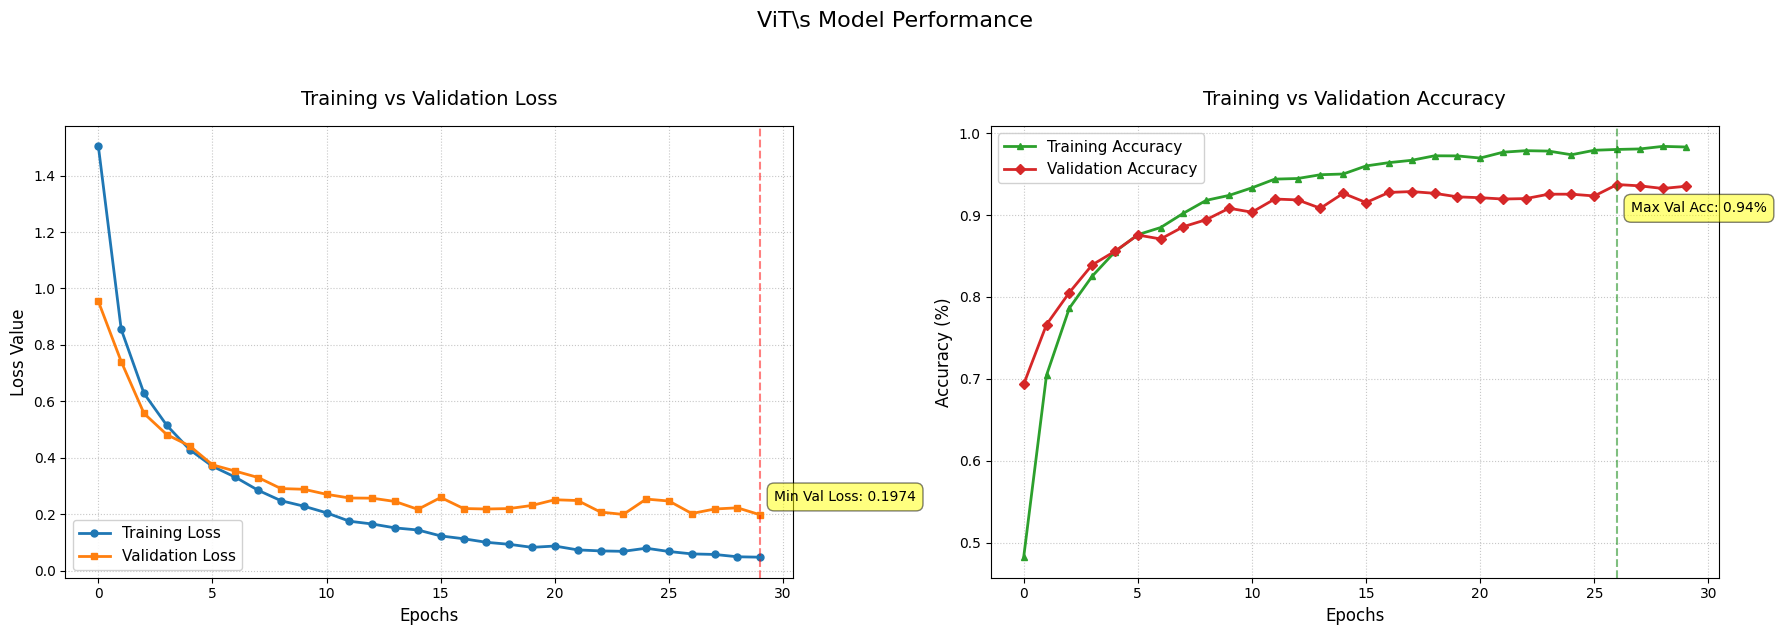

In [29]:
plots_('ViT')

<div dir="rtl">

## ارزیابی مدل با داده های تست

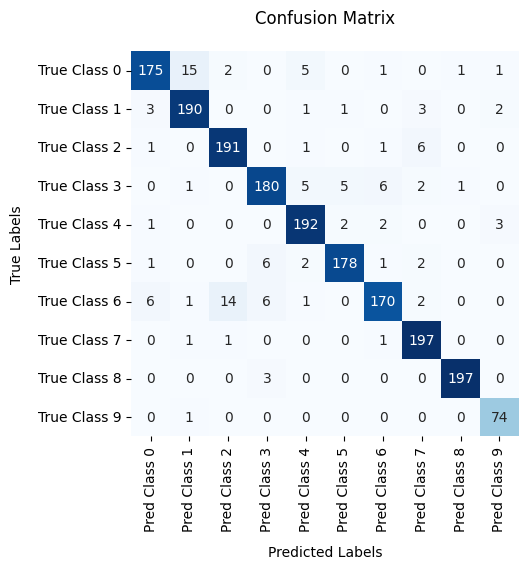

Confusion Matrix:


,Pred Class 0,Pred Class 1,Pred Class 2,Pred Class 3,Pred Class 4,Pred Class 5,Pred Class 6,Pred Class 7,Pred Class 8,Pred Class 9
True Class 0,175,15,2,0,5,0,1,0,1,1
True Class 1,3,190,0,0,1,1,0,3,0,2
True Class 2,1,0,191,0,1,0,1,6,0,0
True Class 3,0,1,0,180,5,5,6,2,1,0
True Class 4,1,0,0,0,192,2,2,0,0,3
True Class 5,1,0,0,6,2,178,1,2,0,0
True Class 6,6,1,14,6,1,0,170,2,0,0
True Class 7,0,1,1,0,0,0,1,197,0,0
True Class 8,0,0,0,3,0,0,0,0,197,0
True Class 9,0,1,0,0,0,0,0,0,0,74



Classification Report:


,precision,recall,f1-score,support
Class 0,0.9358,0.8750,0.9044,200.0
Class 1,0.9091,0.9500,0.9291,200.0
Class 2,0.9183,0.9550,0.9363,200.0
Class 3,0.9231,0.9000,0.9114,200.0
Class 4,0.9275,0.9600,0.9435,200.0
Class 5,0.9570,0.9368,0.9468,190.0
Class 6,0.9341,0.8500,0.8901,200.0
Class 7,0.9292,0.9850,0.9563,200.0
Class 8,0.9899,0.9850,0.9875,200.0
Class 9,0.9250,0.9867,0.9548,75.0


accuracy 0.9351


In [30]:
results = evaluate_model_to_dataframe(model, val_loader)
print("Confusion Matrix:")
display(results['confusion_matrix'])
print("\nClassification Report:")
display(results['classification_report'][:10])
print('accuracy', float(results['classification_report'].iloc[10]['precision']))

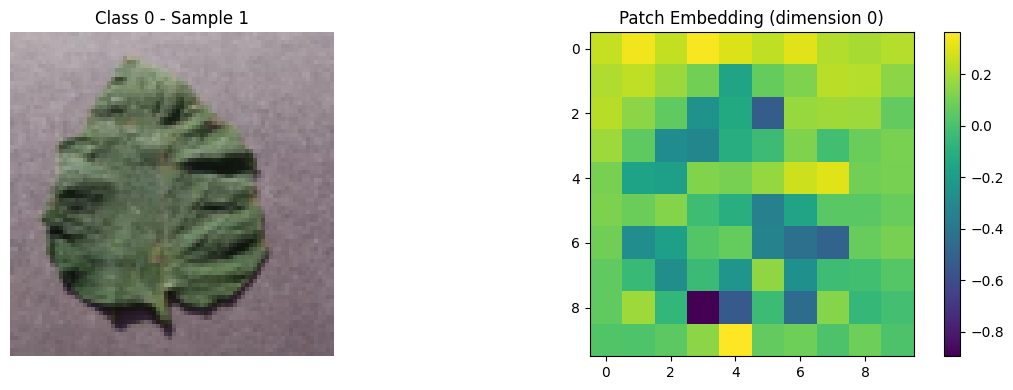

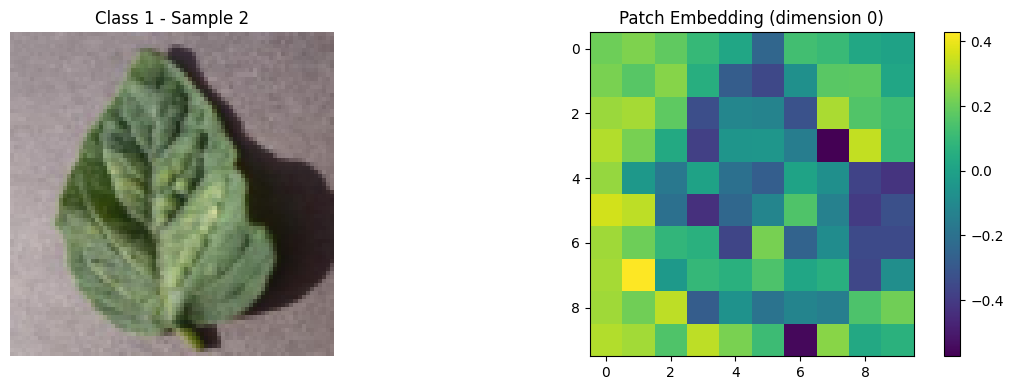

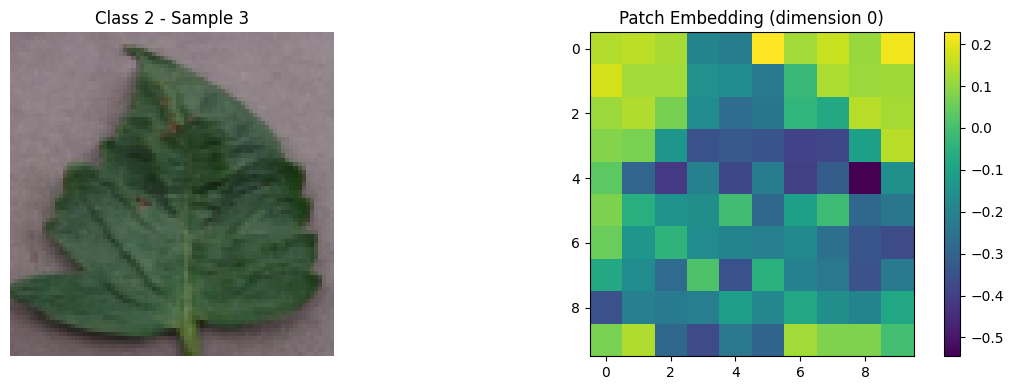

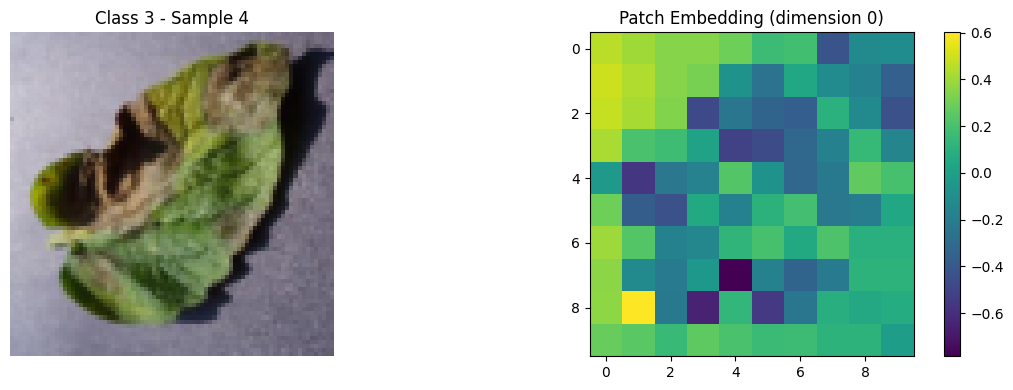

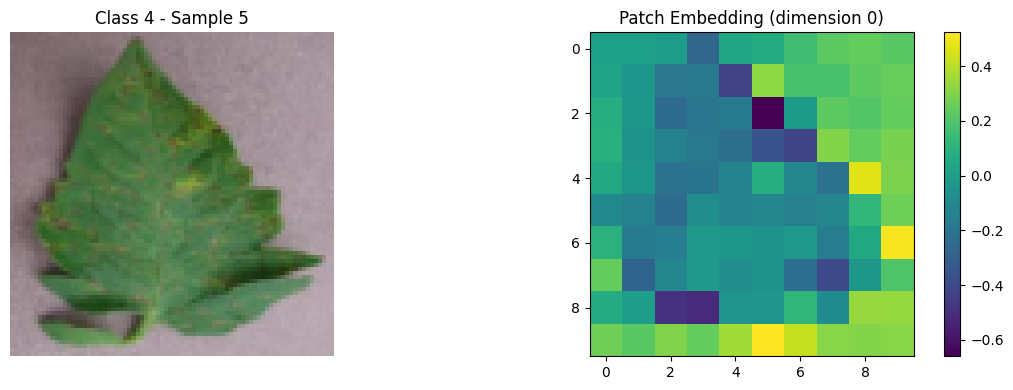

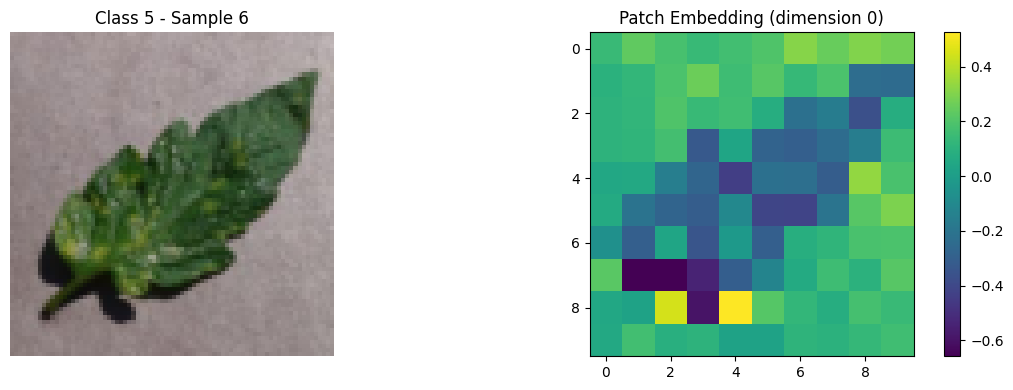

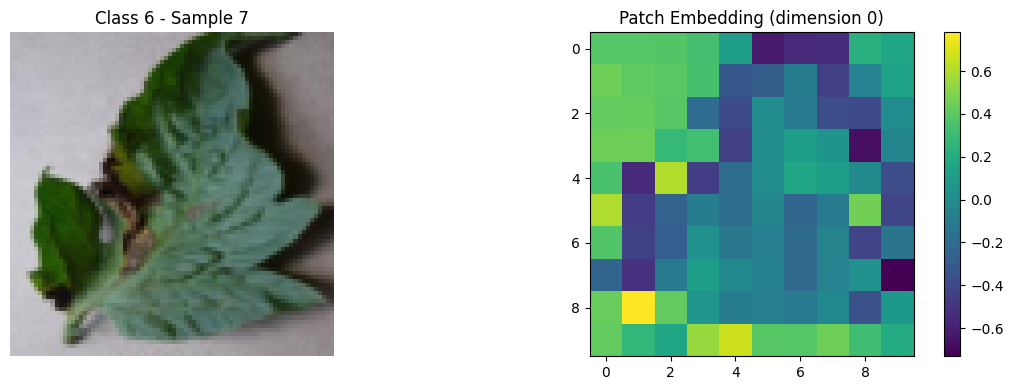

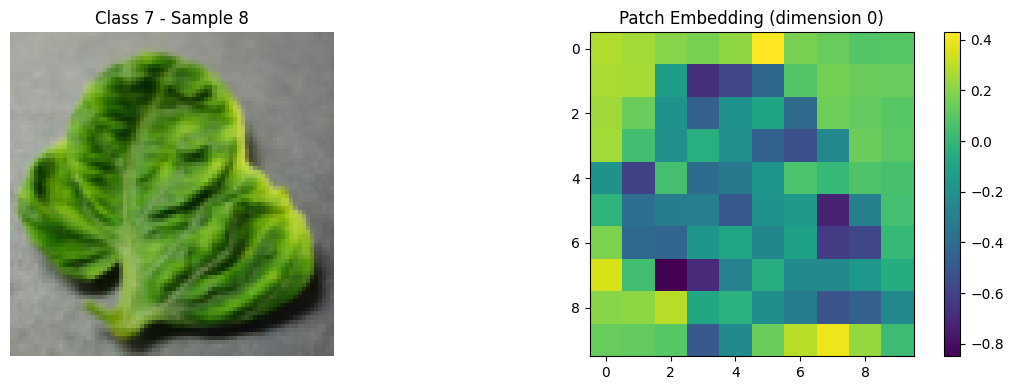

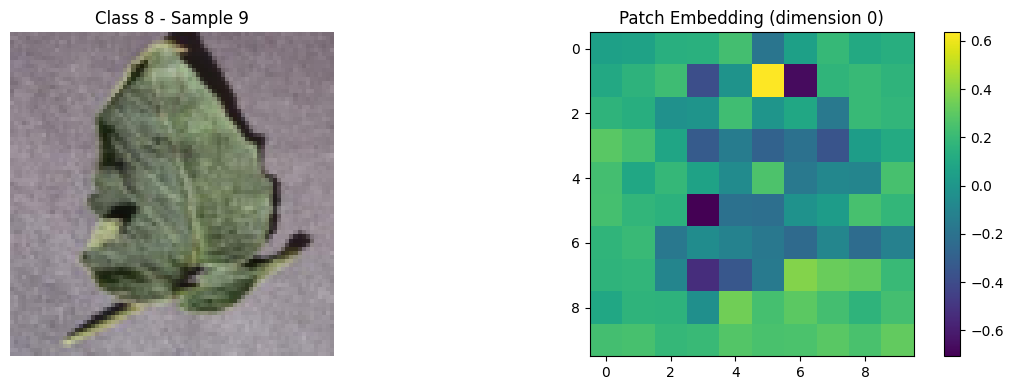

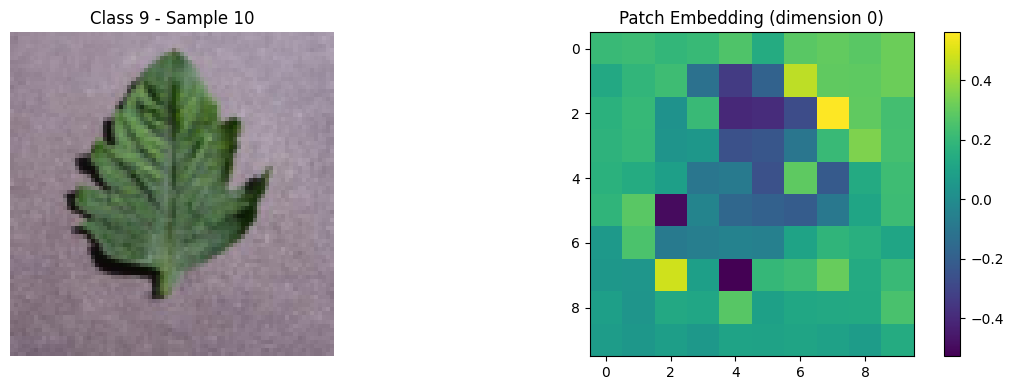

In [31]:
import matplotlib.pyplot as plt
import torch

# Set model to evaluation mode
model.eval()

# Dictionary to store one sample per class
selected_samples = {}

# Run inference and collect one sample per class
with torch.no_grad():
    for inputs, labels in val_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)
        _ = model(inputs)
        patch_embed = model.last_patch_embedding.cpu().numpy()

        for i in range(inputs.size(0)):
            label_id = labels[i].item()
            if label_id not in selected_samples:
                selected_samples[label_id] = (
                    inputs[i].cpu(),
                    labels[i].cpu(),
                    patch_embed[i]
                )
            if len(selected_samples) == 10:
                break
        if len(selected_samples) == 10:
            break

# Sort samples by class label
sorted_samples = sorted(selected_samples.items())

# Visualize one sample per class
for idx, (label_id, (img_tensor, label, embed)) in enumerate(sorted_samples):
    plt.figure(figsize=(12, 4))

    # Convert normalized tensor image to displayable format
    img = img_tensor.permute(1, 2, 0)  # CHW → HWC
    img = (img * torch.tensor([0.229, 0.224, 0.225]) +
           torch.tensor([0.485, 0.456, 0.406])).clip(0, 1)

    # Show original image
    plt.subplot(1, 2, 1)
    plt.imshow(img)
    plt.title(f"Class {label.item()} - Sample {idx+1}")
    plt.axis('off')

    # Show heatmap of first embedding dimension over 10x10 patch grid
    plt.subplot(1, 2, 2)
    plt.imshow(embed[:, 0].reshape(10, 10), cmap='viridis')
    plt.colorbar()
    plt.title("Patch Embedding (dimension 0)")
    plt.tight_layout()
    plt.show()


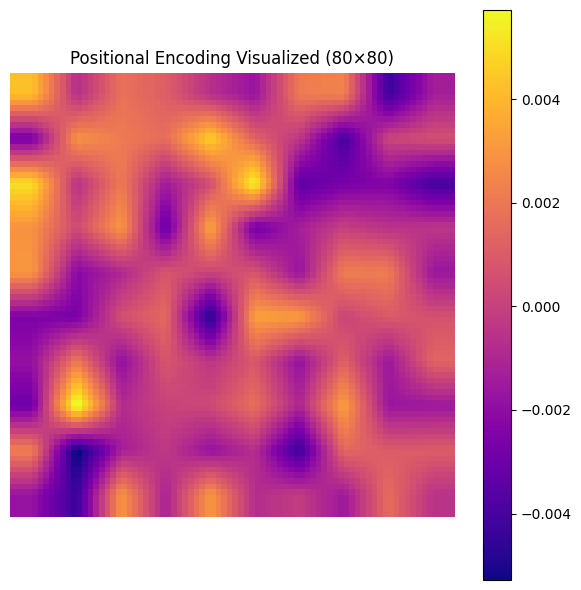

In [33]:
# Get positional embedding weights (shape: [100, 64])
pos_embed_weights = model.pos_embed.weight.detach().cpu()  # [num_patches, emb_dim]

# Option 1: use mean across embedding dimensions
pos_values = pos_embed_weights.mean(dim=1)  # [100]

# Option 2 (alternative): use a specific dimension (e.g., dim 0)
# pos_values = pos_embed_weights[:, 0]  # [100]

# Reshape to 10×10 grid
pos_grid = pos_values.reshape(10, 10)  # (10, 10)

# Upsample to 80×80 using bilinear interpolation
pos_grid_tensor = pos_grid.unsqueeze(0).unsqueeze(0)  # [1, 1, 10, 10]
pos_grid_upsampled = F.interpolate(pos_grid_tensor, size=(80, 80), mode='bilinear', align_corners=False)
pos_img = pos_grid_upsampled.squeeze().numpy()

# Plot the result
plt.figure(figsize=(6, 6))
plt.imshow(pos_img, cmap='plasma')
plt.title("Positional Encoding Visualized (80×80)")
plt.colorbar()
plt.axis('off')
plt.tight_layout()
plt.show()
